# Stacked Bar Chart

**Family:** Part-to-whole &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Part-to-whole:* Show how a single entity breaks down into its components.

## Design purpose

Each bar is a total, divided into segments for its components. It shows the total and its composition at once. The first segment and the total are easy to compare across bars. Inner segments are harder to compare because they have no common baseline.

## When to use

- Compare totals across categories and show roughly what makes them up
- Use few components (2–5), where the first segment is the most important
- Show composition of counts or amounts, not percentages

## Avoid when

- Readers must compare the middle segments precisely (use grouped bars or small multiples)
- There are more than ~5 components
- Only the shares matter, not the totals (use a 100% stacked bar)

## Alternatives

- Grouped bar chart
- 100% stacked bar
- Small-multiple bars

## Design tips

- Put the most important or most stable component on the baseline
- Keep segment order the same in every bar and in the legend
- Separate segments with a thin surface-colored gap, not a dark border

## Example

Quarterly revenue of a software company, split by sales channel.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"

import altair as alt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]


@alt.theme.register("vizlib", enable=True)
def vizlib_theme():
    return alt.theme.ThemeConfig({
        "config": {
            "background": "#fcfcfb",
            "view": {"stroke": None},
            "range": {"category": PALETTE},
            "font": "Helvetica, Arial, sans-serif",
            "title": {"anchor": "start", "fontSize": 14, "color": "#0b0b0b"},
            "axis": {"gridColor": "#e6e5e1", "domainColor": "#c9c8c3", "tickColor": "#c9c8c3",
                     "labelColor": "#52514e", "titleColor": "#52514e", "titleFontWeight": "normal"},
            "legend": {"labelColor": "#52514e", "titleColor": "#52514e"},
        }
    })
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
quarters = ["Q1", "Q2", "Q3", "Q4"]
df = pd.DataFrame({
    "Direct sales": [3200, 3500, 3350, 3800],
    "Partners":     [5400, 5600, 5900, 6100],
    "Online":       [1200, 1500, 1900, 2300],
}, index=quarters)
df

,Direct sales,Partners,Online
Q1,3200,5400,1200
Q2,3500,5600,1500
Q3,3350,5900,1900
Q4,3800,6100,2300


### Plot

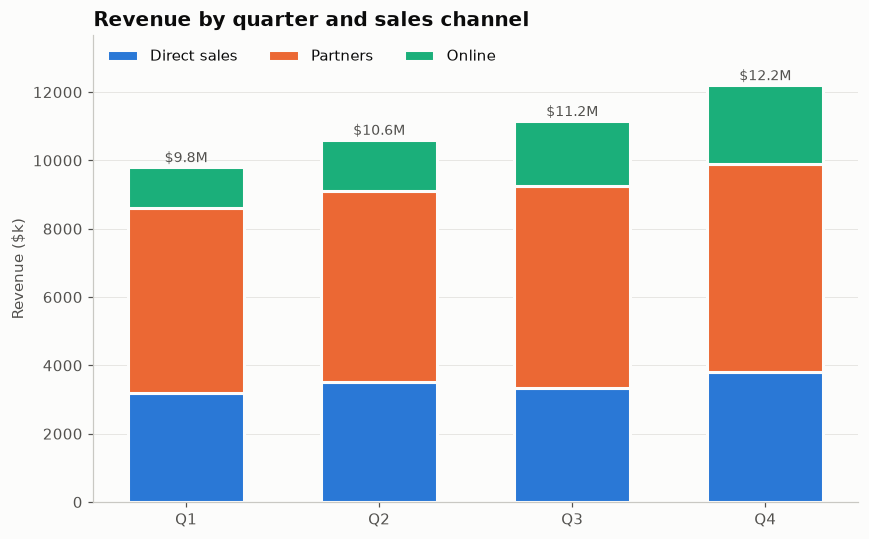

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
bottom = np.zeros(len(df))
for i, col in enumerate(df.columns):
    ax.bar(df.index, df[col], bottom=bottom, color=PALETTE[i], label=col,
           width=0.6, edgecolor="#fcfcfb", linewidth=2)
    bottom += df[col].values
for x, total in enumerate(bottom):
    ax.text(x, total + 150, f"${total / 1000:.1f}M", ha="center", fontsize=9, color="#52514e")
ax.set_ylabel("Revenue ($k)")
ax.set_title("Revenue by quarter and sales channel")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, bottom.max() * 1.12)
ax.legend(ncol=3, loc="upper left")
fig.tight_layout()
plt.show()

## How to read it

Bar height is total revenue in the quarter and each colored segment is one sales channel. Online, the top segment, grows every quarter while the other channels are roughly flat.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.express as px
long = df.rename_axis("quarter").reset_index().melt(id_vars="quarter", var_name="channel", value_name="revenue")
fig = px.bar(long, x="quarter", y="revenue", color="channel", color_discrete_sequence=PALETTE,
             labels={"quarter": "", "revenue": "Revenue ($k)", "channel": ""},
             title="Revenue by quarter and sales channel")
fig.update_traces(marker_line_color="#fcfcfb", marker_line_width=2)
fig.show()

### altair

In [5]:
import altair as alt
long = df.rename_axis("quarter").reset_index().melt(id_vars="quarter", var_name="channel", value_name="revenue")
chart = alt.Chart(long).mark_bar(stroke="#fcfcfb", strokeWidth=2).encode(
    x=alt.X("quarter:N", title=None, axis=alt.Axis(labelAngle=0)),
    y=alt.Y("revenue:Q", title="Revenue ($k)"),
    color=alt.Color("channel:N", sort=list(df.columns), title=None),
    order=alt.Order("stack:Q"), tooltip=["quarter", "channel", "revenue"],
).transform_calculate(stack=f"indexof({list(df.columns)}, datum.channel)"
).properties(title="Revenue by quarter and sales channel", width=380, height=320)
chart

alt.Chart(...)

---
Standalone script: [`stacked_bar.py`](stacked_bar.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)